# 03 — Exploratory Analysis

## 1. Objective

Explore the SWaT dataset to understand sensor behaviour, identify patterns associated with normal and attack observations, and establish evidence to guide anomaly-detection model development.

The analysis will examine sensor distributions, variability, temporal behaviour, relationships between variables, and differences between normal and attack observations.

## 2. Scope

This notebook will:

- Examine the structure and descriptive statistics of the sensor variables.
- Investigate sensor distributions, variability, and potential outliers.
- Compare sensor behaviour between normal and attack observations.
- Examine temporal patterns and changes in sensor behaviour.
- Investigate relationships and dependencies among sensor variables.
- Identify patterns that may inform feature selection, model design, and evaluation.
- Document findings, limitations, and implications for subsequent modelling.

## 3. Data Handling Principles

- Preserve the original files in `data/raw/` without modification.
- Use the existing project paths rather than hardcoded machine-specific paths.
- Account for the missing-data block and duplicated normal-data segment identified in Notebook 02.
- Do not automatically impute missing values or remove observations without a documented rationale.
- Preserve temporal order when analysing time-dependent behaviour.
- Distinguish exploratory findings from conclusions that require further verification.
- Prevent exploratory decisions from using the final test set in ways that compromise evaluation independence.

## 4. Analytical Approach

The analysis will proceed from dataset-level summaries to individual sensor distributions, temporal behaviour, and relationships between variables.

Comparisons between normal and attack observations will be interpreted in the context of the data-quality findings established in Notebook 02. Any observations excluded from particular analyses will be identified, and the rationale will be documented.

## 5. Expected Outcome

By the end of this notebook, the principal characteristics of the sensor data, differences between normal and attack observations, and relevant temporal and multivariate patterns should be documented.

The findings will inform the design of the baseline, traditional machine-learning, and deep-learning anomaly-detection methods in the subsequent notebooks.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        directory
        for directory in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (directory / "data" / "raw").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not locate data/raw from the current directory: {CURRENT_DIR}"
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"

FILES = {
    "normal": DATA_DIR / "normal.csv",
    "attack": DATA_DIR / "attack.csv",
    "merged": DATA_DIR / "merged.csv",
}

for name, path in FILES.items():
    if path.is_file():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{name}: {path.name} | {size_mb:.2f} MB")
    else:
        print(f"{name}: NOT FOUND")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# print(f"\nProject root: {PROJECT_ROOT}")
print("Dataset discovery complete.")

normal: normal.csv | 383.73 MB
attack: attack.csv | 14.46 MB
merged: merged.csv | 407.08 MB
Dataset discovery complete.


In [2]:
import warnings

warnings.filterwarnings('ignore', category=UserWarning)

normal = pd.read_csv(FILES["normal"])
attack = pd.read_csv(FILES["attack"])

normal.columns = normal.columns.str.strip()
attack.columns = attack.columns.str.strip()

TIMESTAMP_COL = "Timestamp"
LABEL_COL = "Normal/Attack"

for name, df in [("normal", normal), ("attack", attack)]:
    if TIMESTAMP_COL not in df.columns:
        raise KeyError(f"{TIMESTAMP_COL!r} not found in {name}.csv")
    
    df[TIMESTAMP_COL] = pd.to_datetime(
        df[TIMESTAMP_COL],
        errors="coerce"
    )
    print(f"\n{name.upper()} DATASET")
    print(f"Shape: {df.shape}")
    print(f"Timestamp parsing failures: {df[TIMESTAMP_COL].isna().sum()}")
    print(f"Duplicate rows: {df.duplicated().sum()}")
    print(f"Labels:\n{df[LABEL_COL].value_counts(dropna=False)}")

print("\nColumn names consistent:", normal.columns.equals(attack.columns))
print("Normal dataset loaded:", normal.shape)
print("Attack dataset loaded:", attack.shape)


NORMAL DATASET
Shape: (1387098, 53)
Timestamp parsing failures: 5
Duplicate rows: 494995
Labels:
Normal/Attack
Normal    1387098
Name: count, dtype: int64

ATTACK DATASET
Shape: (54621, 53)
Timestamp parsing failures: 0
Duplicate rows: 0
Labels:
Normal/Attack
Attack    54621
Name: count, dtype: int64

Column names consistent: True
Normal dataset loaded: (1387098, 53)
Attack dataset loaded: (54621, 53)


In [3]:
normal.loc[
    normal["Timestamp"].isna(),
    ["Timestamp", "Normal/Attack"]
]

,Timestamp,Normal/Attack
450283,NaT,Normal
501943,NaT,Normal
591269,NaT,Normal
669754,NaT,Normal
826710,NaT,Normal


In [4]:
TIMESTAMP_COL = "Timestamp"
LABEL_COL = "Normal/Attack"

feature_cols = [
    col for col in normal.columns
    if col not in (TIMESTAMP_COL, LABEL_COL)
]

normal_inventory = pd.DataFrame({
    "dtype": normal[feature_cols].dtypes.astype(str),
    "missing_count": normal[feature_cols].isna().sum(),
    "missing_pct": normal[feature_cols].isna().mean().mul(100),
    "unique_values": normal[feature_cols].nunique(dropna=True),
})

attack_inventory = pd.DataFrame({
    "dtype": attack[feature_cols].dtypes.astype(str),
    "missing_count": attack[feature_cols].isna().sum(),
    "missing_pct": attack[feature_cols].isna().mean().mul(100),
    "unique_values": attack[feature_cols].nunique(dropna=True),
})

feature_inventory = normal_inventory.add_prefix("normal_").join(
    attack_inventory.add_prefix("attack_")
)

print(f"Number of sensor features: {len(feature_cols)}")
print(f"Normal observations: {len(normal):,}")
print(f"Attack observations: {len(attack):,}")

print("\nFEATURE INVENTORY")
display(feature_inventory)

print("\nFEATURES WITH MISSING VALUES")
display(
    feature_inventory.loc[
        (feature_inventory["normal_missing_count"] > 0)
        | (feature_inventory["attack_missing_count"] > 0)
    ]
)

print("\nNON-NUMERIC SENSOR FEATURES")
print(
    feature_inventory.loc[
        (feature_inventory["normal_dtype"] == "object")
        | (feature_inventory["attack_dtype"] == "object")
    ].index.tolist()
)

print("\nCONSTANT FEATURES")
print(
    feature_inventory.loc[
        (feature_inventory["normal_unique_values"] <= 1)
        | (feature_inventory["attack_unique_values"] <= 1)
    ].index.tolist()
)

Number of sensor features: 51
Normal observations: 1,387,098
Attack observations: 54,621

FEATURE INVENTORY


,normal_dtype,normal_missing_count,normal_missing_pct,normal_unique_values,attack_dtype,attack_missing_count,attack_missing_pct,attack_unique_values
FIT101,float64,0,0.000000,3903,float64,0,0.0,838
LIT101,float64,0,0.000000,11155,float64,0,0.0,5830
MV101,float64,991800,71.501797,3,int64,0,0.0,3
P101,int64,0,0.000000,2,int64,0,0.0,2
P102,int64,0,0.000000,2,int64,0,0.0,2
AIT201,float64,991800,71.501797,2105,float64,0,0.0,618
AIT202,float64,0,0.000000,1763,float64,0,0.0,748
AIT203,float64,0,0.000000,6654,float64,0,0.0,1783
FIT201,float64,0,0.000000,4673,float64,0,0.0,708
MV201,float64,991800,71.501797,3,int64,0,0.0,3



FEATURES WITH MISSING VALUES


,normal_dtype,normal_missing_count,normal_missing_pct,normal_unique_values,attack_dtype,attack_missing_count,attack_missing_pct,attack_unique_values
MV101,float64,991800,71.501797,3,int64,0,0.0,3
AIT201,float64,991800,71.501797,2105,float64,0,0.0,618
MV201,float64,991800,71.501797,3,int64,0,0.0,3
P201,float64,991800,71.501797,2,int64,0,0.0,2
P202,float64,991800,71.501797,1,int64,0,0.0,1
P204,float64,991800,71.501797,1,int64,0,0.0,2
MV303,float64,991800,71.501797,3,int64,0,0.0,3



NON-NUMERIC SENSOR FEATURES
[]

CONSTANT FEATURES
['P202', 'P204', 'P206', 'P301', 'P401', 'P403', 'P404', 'P502', 'P601', 'P603']


In [5]:
normal_sensor_stats = normal[feature_cols].agg(["mean", "std", "min", "max"]).T
attack_sensor_stats = attack[feature_cols].agg(["mean", "std", "min", "max"]).T

normal_sensor_stats["unique_values"] = normal[feature_cols].nunique()
attack_sensor_stats["unique_values"] = attack[feature_cols].nunique()

sensor_variability = pd.DataFrame({
    "normal_unique_values": normal_sensor_stats["unique_values"],
    "normal_std": normal_sensor_stats["std"],
    "attack_unique_values": attack_sensor_stats["unique_values"],
    "attack_std": attack_sensor_stats["std"],
})

sensor_variability["constant_in_normal"] = (
    sensor_variability["normal_unique_values"] == 1
)
sensor_variability["constant_in_attack"] = (
    sensor_variability["attack_unique_values"] == 1
)

print("CONSTANT FEATURES IN NORMAL DATA")
display(
    sensor_variability.loc[sensor_variability["constant_in_normal"]]
)

print("CONSTANT FEATURES IN ATTACK DATA")
display(
    sensor_variability.loc[sensor_variability["constant_in_attack"]]
)

print("FEATURES CONSTANT IN BOTH DATASETS")
display(
    sensor_variability.loc[
        sensor_variability["constant_in_normal"]
        & sensor_variability["constant_in_attack"]
    ]
)

print("FEATURES WITH THE LOWEST NORMAL-DATA VARIABILITY")
display(
    sensor_variability.sort_values(
        "normal_std",
        na_position="first"
    ).head(15)
)

CONSTANT FEATURES IN NORMAL DATA


,normal_unique_values,normal_std,attack_unique_values,attack_std,constant_in_normal,constant_in_attack
P202,1,0.0,1,0.000000,True,True
P204,1,0.0,2,0.032003,True,False
P206,1,0.0,2,0.031717,True,False
P401,1,0.0,1,0.000000,True,True
P404,1,0.0,1,0.000000,True,True
P502,1,0.0,1,0.000000,True,True
P601,1,0.0,1,0.000000,True,True
P603,1,0.0,1,0.000000,True,True


CONSTANT FEATURES IN ATTACK DATA


,normal_unique_values,normal_std,attack_unique_values,attack_std,constant_in_normal,constant_in_attack
P202,1,0.000000,1,0.0,True,True
P301,2,0.051925,1,0.0,False,True
P401,1,0.000000,1,0.0,True,True
P403,2,0.006577,1,0.0,False,True
P404,1,0.000000,1,0.0,True,True
P502,1,0.000000,1,0.0,True,True
P601,1,0.000000,1,0.0,True,True
P603,1,0.000000,1,0.0,True,True


FEATURES CONSTANT IN BOTH DATASETS


,normal_unique_values,normal_std,attack_unique_values,attack_std,constant_in_normal,constant_in_attack
P202,1,0.0,1,0.0,True,True
P401,1,0.0,1,0.0,True,True
P404,1,0.0,1,0.0,True,True
P502,1,0.0,1,0.0,True,True
P601,1,0.0,1,0.0,True,True
P603,1,0.0,1,0.0,True,True


FEATURES WITH THE LOWEST NORMAL-DATA VARIABILITY


,normal_unique_values,normal_std,attack_unique_values,attack_std,constant_in_normal,constant_in_attack
P204,1,0.000000,2,0.032003,True,False
P206,1,0.000000,2,0.031717,True,False
P202,1,0.000000,1,0.000000,True,True
P401,1,0.000000,1,0.000000,True,True
P601,1,0.000000,1,0.000000,True,True
P603,1,0.000000,1,0.000000,True,True
P502,1,0.000000,1,0.000000,True,True
P404,1,0.000000,1,0.000000,True,True
P403,2,0.006577,1,0.000000,False,True
P102,2,0.008319,2,0.228868,False,False


## 6. Sensor Feature Variability

### 6.1 Feature Inventory

The dataset contains 51 sensor features, comprising 1,387,098 normal observations and 54,621 attack observations. All 51 sensor features have numeric data types in both datasets.

The feature inventory identified seven sensors with missing values in the normal dataset: `MV101`, `AIT201`, `MV201`, `P201`, `P202`, `P204`, and `MV303`. Each contains 991,800 missing values, representing approximately 71.50% of normal observations. No missing sensor values were identified in the attack dataset.

These missing values correspond to the missing-data block identified during the data-quality investigation in Notebook 02. The affected features require special consideration during subsequent preprocessing and model development. No imputation or feature removal is performed at this stage.

### 6.2 Constant Features

The variability analysis identified six features with only one observed value in both datasets:

- `P202`
- `P401`
- `P404`
- `P502`
- `P601`
- `P603`

Because these features do not vary in either dataset, they provide no observed variation for distinguishing normal from attack observations in the current data. They are candidates for exclusion from the modelling feature set, subject to confirmation during preprocessing.

Four additional features exhibit constant behaviour in one dataset but variation in the other:

| Feature | Normal unique values | Attack unique values |
|---|---:|---:|
| `P204` | 1 | 2 |
| `P206` | 1 | 2 |
| `P301` | 2 | 1 |
| `P403` | 2 | 1 |

These features will not be classified as globally constant because their observed values differ between the datasets. Their behaviour should be retained for further investigation rather than dismissed solely on the basis of variability within the normal dataset.

### 6.3 Near-Constant Features

The standard-deviation analysis identified low-variability features, including `P102`, `FIT504`, and `FIT503`, in addition to the constant features listed above.

Low variability alone is insufficient justification for removing a feature. A sensor may exhibit small numerical changes that are operationally meaningful or may behave differently during an attack. Further distributional and temporal analysis is therefore required before deciding whether any near-constant feature should be excluded.

### 6.4 Timestamp Considerations

Five normal observations have timestamps that could not be parsed successfully. These observations remain relevant to sensor-level analysis but require care in analyses that depend on valid timestamps.

The previously identified duplicated normal-data segment and missing-data block also limit the interpretation of temporal plots. These issues must be considered when constructing chronological training, validation, and test datasets.

The previously identified duplicated normal-data segment and missing-data block also limit the interpretation of temporal plots. These issues must be considered when constructing chronological training, validation, and test datasets.

A separate count obtained during dataset loading reports 494,995 exact-duplicate rows for `normal.csv`. Notebook 02 established 495,000 duplicate rows beyond the first occurrences in the affected segment. The 5-row difference coincides with the 5 rows whose timestamps could not be parsed after `pd.to_datetime(..., errors='coerce')`, but this has not been independently confirmed and should be reconciled before any temporal split is finalised.

### 6.5 Implications for Subsequent Analysis

The exploratory analysis will proceed without modifying the raw datasets or automatically removing features.

The next analyses will examine selected sensor time series, compare sensor distributions between normal and attack observations, and investigate relationships between sensor variables. These analyses will help establish which features exhibit potentially informative behaviour and guide subsequent preprocessing and anomaly-detection model development.

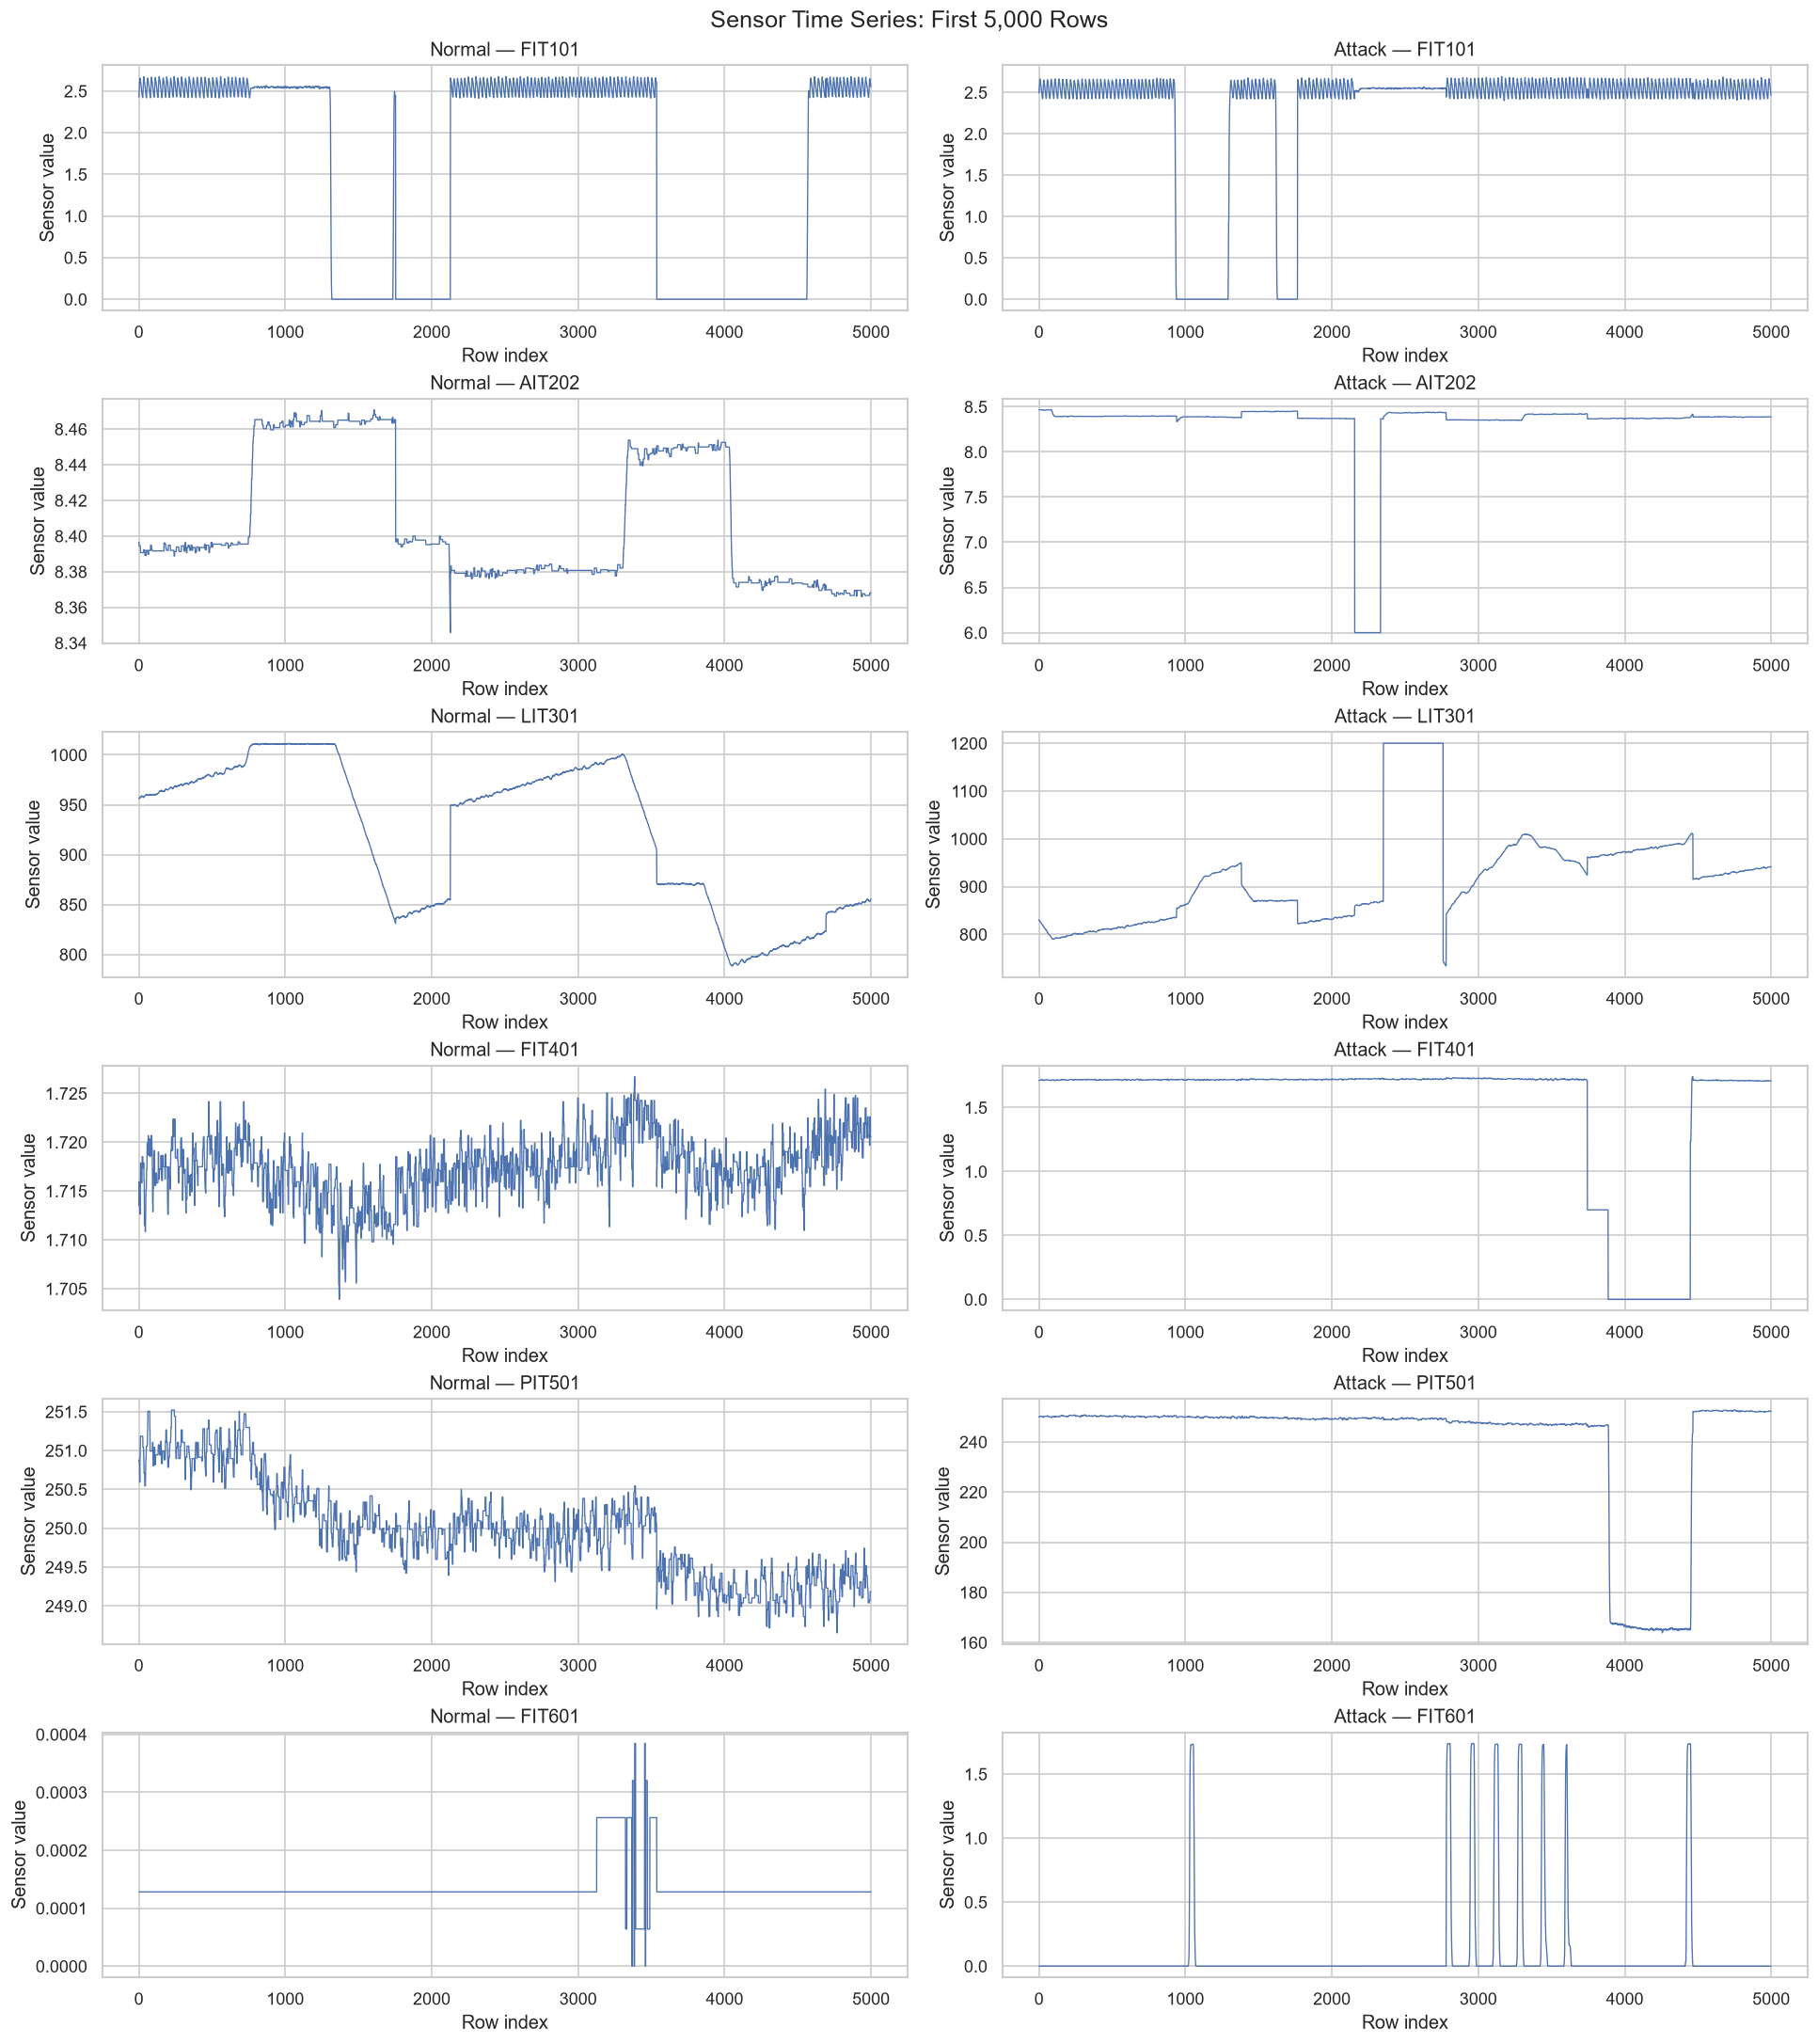

In [6]:
selected_sensors = [
    "FIT101",
    "AIT202",
    "LIT301",
    "FIT401",
    "PIT501",
    "FIT601",
]

missing_sensors = [
    sensor for sensor in selected_sensors
    if sensor not in normal.columns or sensor not in attack.columns
]

if missing_sensors:
    raise KeyError(f"Selected sensors not found in both datasets: {missing_sensors}")

plot_rows = 5000

fig, axes = plt.subplots(
    len(selected_sensors),
    2,
    figsize=(16, 18),
    constrained_layout=True,
)

for row, sensor in enumerate(selected_sensors):
    axes[row, 0].plot(
        normal[sensor].iloc[:plot_rows].to_numpy(),
        linewidth=0.8,
    )
    axes[row, 0].set_title(f"Normal — {sensor}")
    axes[row, 0].set_xlabel("Row index")
    axes[row, 0].set_ylabel("Sensor value")

    axes[row, 1].plot(
        attack[sensor].iloc[:plot_rows].to_numpy(),
        linewidth=0.8,
    )
    axes[row, 1].set_title(f"Attack — {sensor}")
    axes[row, 1].set_xlabel("Row index")
    axes[row, 1].set_ylabel("Sensor value")

fig.suptitle(
    f"Sensor Time Series: First {plot_rows:,} Rows",
    fontsize=15,
)

plt.show()

## 7. Sensor Time-Series Analysis

### 7.1 Observed Sensor Behaviour

The first 5,000 rows of six selected sensor features were plotted separately for the normal and attack datasets. The selection follows the reference implementation and includes `FIT101`, `AIT202`, `LIT301`, `FIT401`, `PIT501`, and `FIT601`.

The plots reveal differences in observed sensor behaviour between the two datasets:

- **FIT101:** Both datasets exhibit changes between higher and lower values. The attack observations contain several distinct low-value intervals.
- **AIT202:** The normal observations show several changes in operating level, while the attack observations are comparatively stable apart from a pronounced downward excursion.
- **LIT301:** Both datasets exhibit substantial changes in level. The attack observations include a pronounced upward excursion and subsequent changes in the observed trend.
- **FIT401:** The normal observations fluctuate within a relatively narrow range. The attack observations contain a pronounced reduction to zero followed by a return to a higher level.
- **PIT501:** The normal observations show fluctuations and changes in operating level. The attack observations contain a substantial downward excursion followed by a recovery.
- **FIT601:** The normal observations are mostly stable, with several short-lived changes. The attack observations contain multiple isolated spikes against a predominantly zero-valued series.

### 7.2 Interpretation and Limitations

These plots provide preliminary evidence that selected sensors exhibit different patterns in the normal and attack datasets. The observed differences include changes in operating level, short-lived excursions, fluctuations, and isolated spikes.

The plots use row indices rather than timestamps and show only the first 5,000 rows of each dataset. The observations therefore do not establish the behaviour of the complete datasets or identify the precise timing and operational cause of individual changes.

The temporal integrity issues identified in Notebook 02 must also be considered when interpreting these patterns. Further analysis is required to quantify differences between normal and attack observations and assess their relevance to anomaly detection.

### 7.3 Implications for Subsequent Analysis

The observed differences justify further investigation of sensor distributions and relationships between features. However, no feature is selected or excluded solely on the basis of these plots.

The next analysis will compare the distributions of the selected sensor features between the normal and attack datasets.

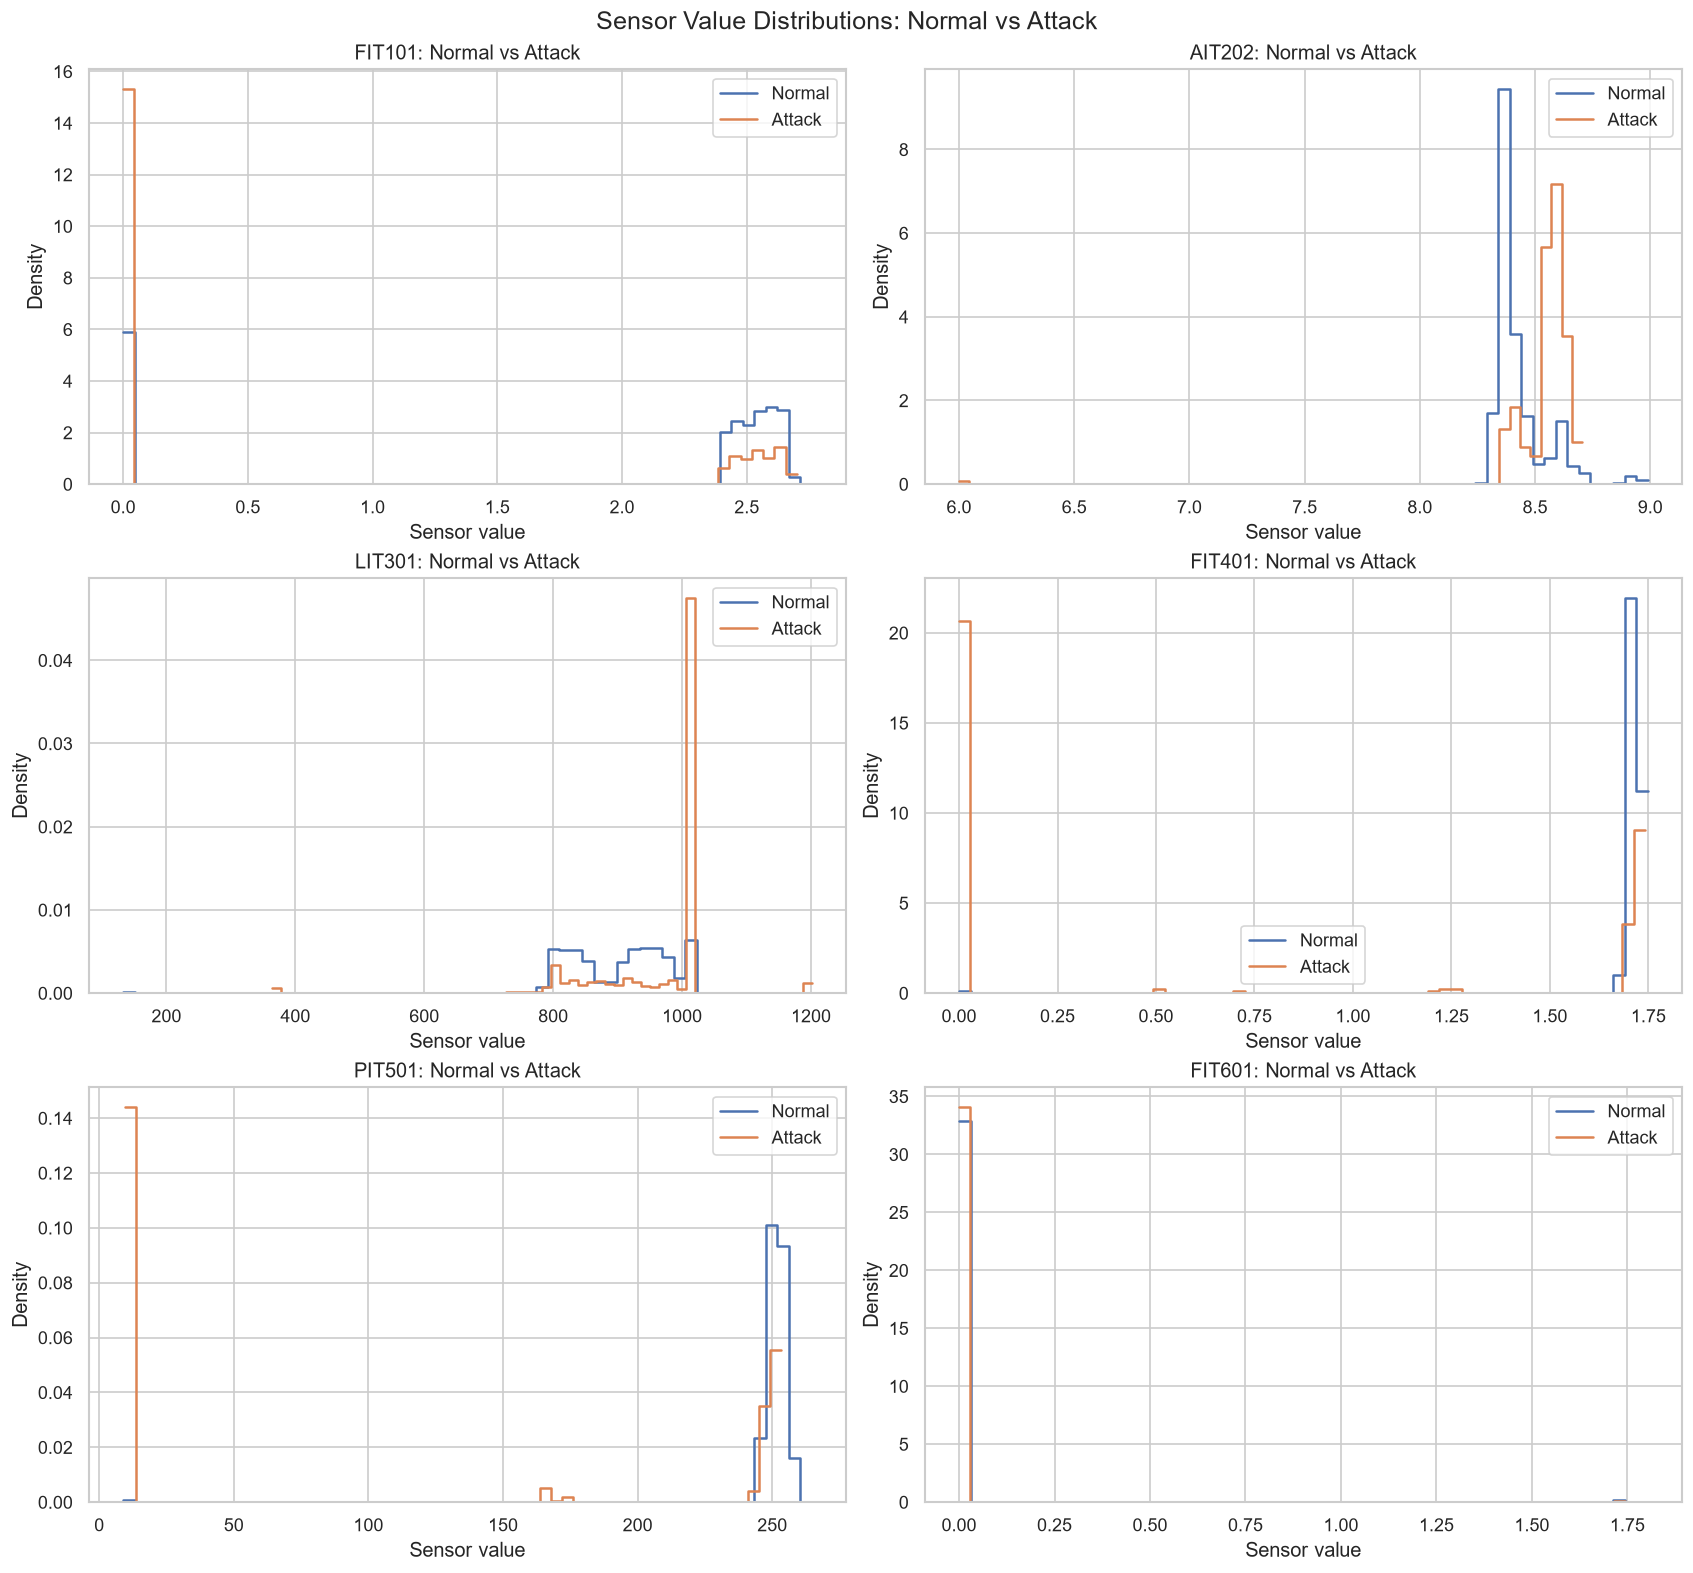

In [7]:
selected_sensors = [
    "FIT101",
    "AIT202",
    "LIT301",
    "FIT401",
    "PIT501",
    "FIT601",
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 13),
    constrained_layout=True,
)

for ax, sensor in zip(axes.flat, selected_sensors):
    sns.histplot(
        normal[sensor].dropna(),
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label="Normal",
        ax=ax,
    )

    sns.histplot(
        attack[sensor].dropna(),
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label="Attack",
        ax=ax,
    )

    ax.set_title(f"{sensor}: Normal vs Attack")
    ax.set_xlabel("Sensor value")
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle(
    "Sensor Value Distributions: Normal vs Attack",
    fontsize=15,
)

plt.show()

## 8. Normal-versus-Attack Sensor Distributions

### 8.1 Distributional Differences

The distributions of six selected sensor features were compared between the normal and attack datasets using density histograms. Density normalization was used to accommodate the difference in dataset sizes.

The plots reveal several differences:

- **FIT101:** Both datasets contain values near zero and a higher operating range around 2.4–2.7. Their relative distributions across these regions differ.
- **AIT202:** The attack distribution is concentrated at somewhat higher values than the normal distribution.
- **LIT301:** The normal distribution spans several operating levels, whereas the attack distribution exhibits a pronounced concentration around 1,000 alongside values at other levels.
- **FIT401:** The normal distribution is concentrated around 1.7. The attack distribution includes values near zero and additional intermediate values.
- **PIT501:** The attack distribution includes a pronounced low-value region around 15–20, while most normal observations are concentrated around 245–260.
- **FIT601:** Both distributions are dominated by zero-valued observations, with relatively few nonzero values.

### 8.2 Interpretation

The observed differences indicate that selected sensors exhibit different value distributions in the normal and attack datasets. Potentially informative patterns include shifts in operating levels, additional low-value observations, and differences in the concentration of sensor values.

However, the histograms combine observations across time and do not establish when the differences occurred or whether they were caused by attacks. Distributional separation alone does not demonstrate that a feature can reliably distinguish attacks from normal operating conditions.

The prominent concentrations near zero and the isolated values in some plots also warrant further investigation. These observations should not automatically be treated as missing values, measurement errors, or anomalies without additional evidence.

### 8.3 Limitations

This comparison covers six selected features rather than all 51 sensor features. It also does not account for temporal dependencies or the operational sequence of sensor observations.

The results are therefore exploratory and will be considered alongside temporal analysis, feature relationships, and subsequent model evaluation.

### 8.4 Implications for Subsequent Analysis

The distributional differences support further investigation of sensor relationships and temporal behaviour. No feature will be selected or excluded solely on the basis of these histograms.

The next analysis will examine correlations among sensor features to identify potential dependencies and redundant information.

Rows available for correlation analysis: 395,298
Sensor features included: 51
Rows excluded because of missing sensor values: 991,800


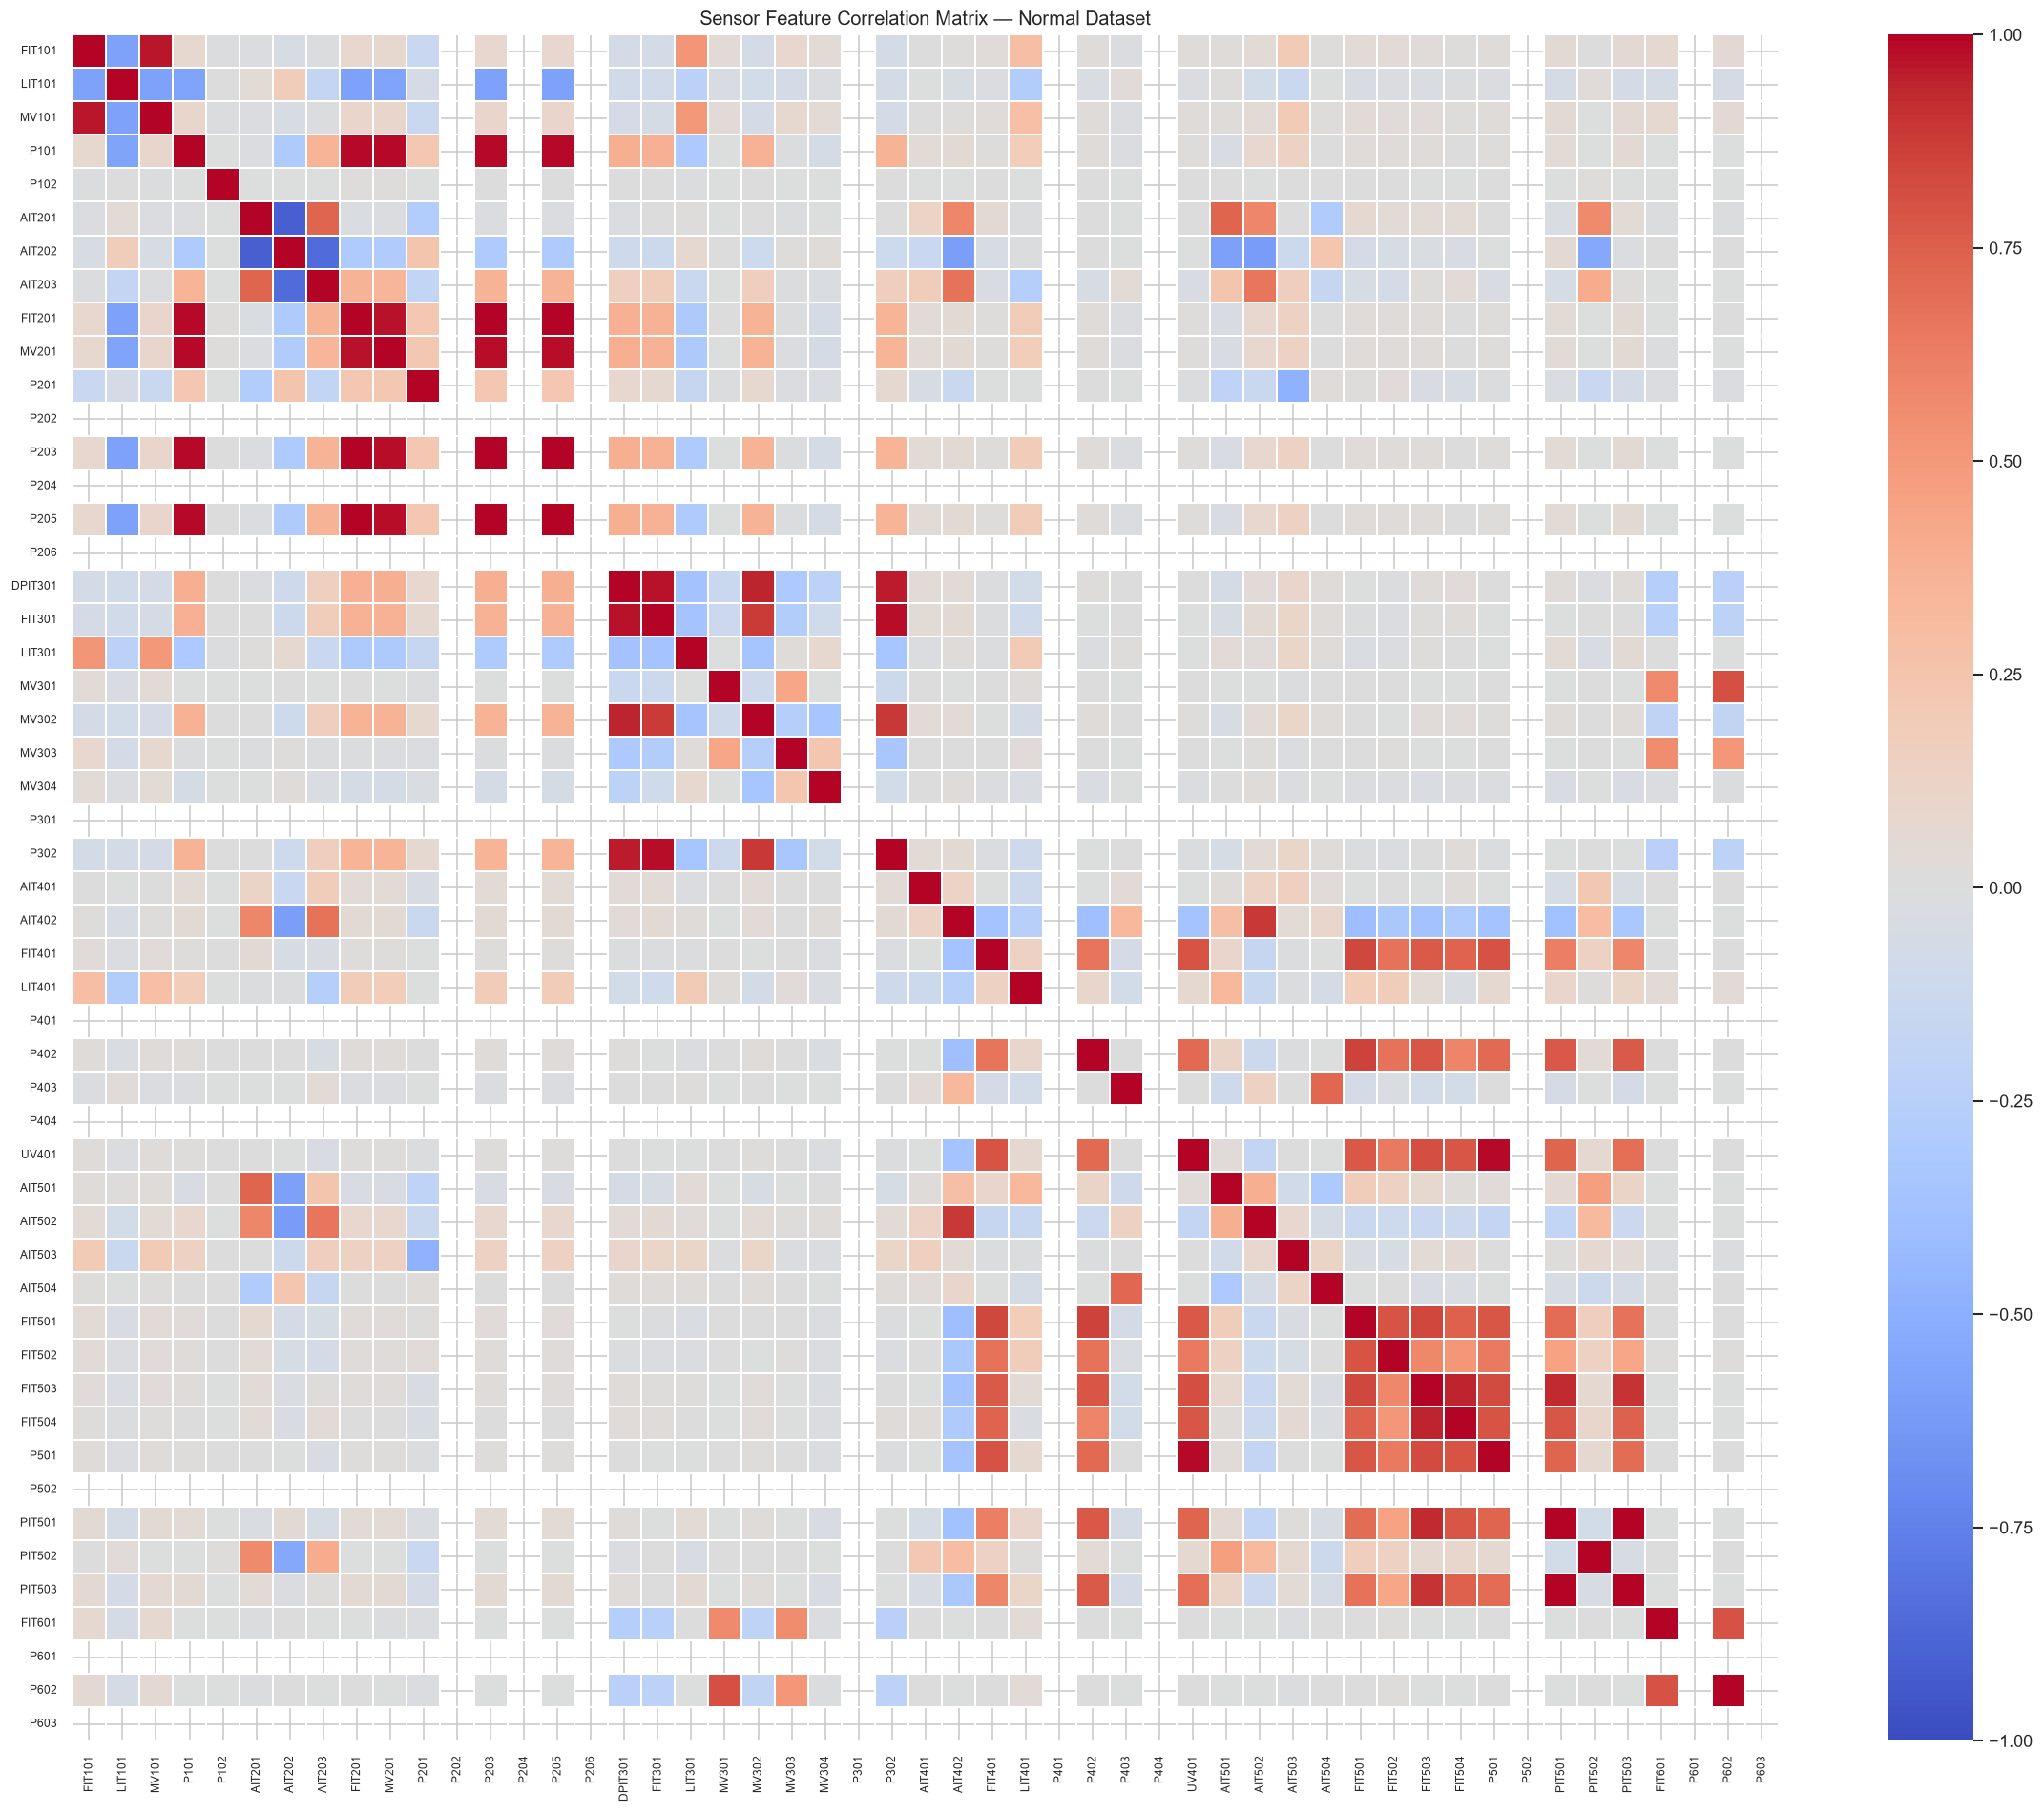

In [8]:
correlation_data = normal[feature_cols].dropna()

correlation_matrix = correlation_data.corr()

print(f"Rows available for correlation analysis: {len(correlation_data):,}")
print(f"Sensor features included: {len(correlation_matrix.columns)}")
print(
    f"Rows excluded because of missing sensor values: "
    f"{len(normal) - len(correlation_data):,}"
)

plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.1,
    xticklabels=True,
    yticklabels=True,
)

plt.title("Sensor Feature Correlation Matrix — Normal Dataset")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

## 9. Sensor Correlation Analysis

### 9.1 Observations

The Pearson correlation matrix — computed on the 395,298 complete-case rows from the pre-missing-block normal segment; the 991,800 rows containing missing sensor values, including the duplicated segment, are excluded — indicates a structured pattern of relationships among sensor features.

The heatmap shows groups of positively correlated sensors, some negatively correlated pairs, and many relationships with relatively weak linear correlation.

The diagonal contains correlation coefficients of 1, as each sensor is perfectly correlated with itself.

### 9.2 Interpretation

The observed correlation structure suggests that normal SWaT operation involves relationships among multiple sensor variables rather than a collection of entirely independent signals.

Positive correlations indicate that sensor values tend to increase or decrease together, while negative correlations indicate that higher values of one sensor tend to be associated with lower values of another.

These relationships may provide useful context for multivariate anomaly detection. An observation that departs from established relationships among sensors may warrant further investigation, even when an individual sensor value appears plausible.

However, the specific strength and operational meaning of these relationships must be established from the underlying correlation coefficients. Correlation alone does not establish causation or demonstrate that a relationship will be disrupted during an attack.

### 9.3 Limitations

This analysis uses the normal dataset and therefore does not establish whether the observed relationships differ during attacks.

Pearson correlation measures linear association and may not capture nonlinear dependencies. Because the duplicated segment lies entirely within the excluded missing-value block, it does not affect the correlation coefficients reported here.

The findings are exploratory. The correlation matrix will inform subsequent investigation but will not, by itself, determine which features are retained or removed.

### 9.4 Implications for Model Development

The observed multivariate structure supports investigating anomaly-detection methods that consider relationships among sensor features.

Subsequent modelling will assess whether these relationships help distinguish anomalous observations from normal process behaviour, using temporally appropriate evaluation and avoiding decisions based on the final test set.

## 10. Exploratory Analysis — Summary of Findings

### 10.1 Dataset Characteristics

The exploratory analysis examined 51 sensor features across 1,387,098 normal observations and 54,621 attack observations.

The feature inventory identified seven sensors with substantial missingness in the normal dataset. These missing values are associated with the data-quality issues investigated in Notebook 02 and require explicit handling during preprocessing.

### 10.2 Sensor Behaviour

Time-series plots and distribution comparisons for six selected sensors revealed differences between the normal and attack datasets. The observed differences included changes in operating levels, low-value intervals, isolated spikes, and differences in the spread and concentration of sensor values.

These findings provide exploratory evidence of potentially informative sensor behaviour. They do not establish that individual sensors can reliably distinguish attacks from normal operating conditions.

### 10.3 Feature Variability

Six features were constant in both datasets: `P202`, `P401`, `P404`, `P502`, `P601`, and `P603`.

These features are candidates for exclusion from the modelling feature set because they exhibit no observed variation in the datasets examined. The final feature set will be determined during preprocessing.

Other features that were constant in only one dataset will not automatically be excluded.

### 10.4 Relationships Between Sensors

The correlation matrix indicates that sensor variables exhibit varying degrees of linear association. The observed structure supports further investigation of multivariate relationships during anomaly detection.

The correlation estimates are computed on complete-case observations only: 395,298 rows from the first normal segment. Because the duplicated segment lies inside the missing-value block, it is excluded from this analysis and does not affect the reported coefficients.

### 10.5 Data Quality and Analytical Limitations

The findings must be interpreted in the context of the data-quality issues established in Notebook 02, including:

- Missing values affecting seven normal-data sensor features.
- A duplicated segment in the normal dataset.
- Five normal observations with timestamps that failed parsing.
- Differences in dataset size and the temporal coverage of normal and attack observations.

The time-series plots cover only the first 5,000 rows of each dataset. The distribution comparisons cover six selected features, and the correlation analysis examines linear relationships rather than all possible dependencies.

### 10.6 Implications for Modelling

The exploratory findings motivate further investigation of sensor behaviour using baseline, traditional machine-learning, and deep-learning anomaly-detection methods.

Before model training, preprocessing must address missing sensor values, constant features, temporal integrity, and the separation of training, validation, and test observations.

All preprocessing and model-selection decisions must preserve the independence of the final test set. The exploratory findings will inform these decisions but will not substitute for evaluation on appropriately partitioned data.

### 10.7 Conclusion

The exploratory analysis identified differences in sensor distributions and observed time-series behaviour between the normal and attack datasets, as well as structured relationships among sensor variables.

These findings establish an initial understanding of the sensor data and provide a basis for subsequent anomaly-detection modelling. They remain exploratory and must be validated through temporally appropriate model development and evaluation.